# Inicializacion constantes


In [1]:
# Importación de librerías necesarias
import numpy as np
import matplotlib.pyplot as plt
import time

# --- CONSTANTES FÍSICAS ---
# Constante de Boltzmann (J/K)
k_B = 1.380649e-23 
# Temperatura ambiente en Kelvin (aprox 27 °C)
T = 300.0           
# Energía mínima para destruir 1 bit (Joules)
E_bit = k_B * T * np.log(2) 
# Asumimos que un entero en Python ocupa 64 bits
W_BITS = 64         

print(f"Energía de borrar 1 bit a {T}K: {E_bit:.4e} Joules")

Energía de borrar 1 bit a 300.0K: 2.8710e-21 Joules


# Algoritmo O(n^2)

In [2]:
def insertion_sort_energy(arr):
    arr = arr.copy() # Copia para no modificar el arreglo original
    bits_destroyed = 0
    
    for i in range(1, len(arr)):
        key = arr[i]
        j = i - 1
        while j >= 0 and arr[j] > key:
            arr[j + 1] = arr[j] # Sobrescritura -> Destruye 64 bits
            bits_destroyed += W_BITS
            j -= 1
        arr[j + 1] = key # Inserción final -> Destruye 64 bits
        bits_destroyed += W_BITS
        
    return bits_destroyed

# Prueba rápida con un arreglo pequeño
test_arr = [5, 2, 4, 6, 1, 3]
bits_test_ins = insertion_sort_energy(test_arr)
print(f"Insertion Sort destruyó {bits_test_ins} bits en el arreglo de prueba.")

Insertion Sort destruyó 896 bits en el arreglo de prueba.


# Algoritmo O(n log n)

In [3]:
def merge_sort_energy(arr):
    arr = arr.copy()
    bits_destroyed = [0] # Lista para poder modificar el valor por referencia
    
    def merge(left, right):
        result = []
        i = j = 0
        # Fusión de los dos sub-arreglos
        while i < len(left) and j < len(right):
            if left[i] < right[j]:
                result.append(left[i])
                i += 1
            else:
                result.append(right[j])
                j += 1
            bits_destroyed[0] += W_BITS # Escritura en memoria auxiliar
            
        # Agregar los elementos restantes
        result.extend(left[i:])
        result.extend(right[j:])
        bits_destroyed[0] += (len(left[i:]) + len(right[j:])) * W_BITS
        return result

    def sort(sub_arr):
        if len(sub_arr) <= 1: return sub_arr
        mid = len(sub_arr) // 2
        left = sort(sub_arr[:mid])
        right = sort(sub_arr[mid:])
        return merge(left, right)

    sort(arr)
    return bits_destroyed[0]

# Prueba rápida
bits_test_mer = merge_sort_energy(test_arr)
print(f"Merge Sort destruyó {bits_test_mer} bits en el arreglo de prueba.")

Merge Sort destruyó 1024 bits en el arreglo de prueba.


# Simulacion

In [4]:
# Definimos los tamaños de arreglo a probar (puedes aumentarlos si tu PC es rápida)
n_values = [10, 50, 100, 200, 500, 1000, 2000, 3000]

# Listas para guardar resultados
energy_insertion = []
energy_merge = []
time_insertion = []
time_merge = []

print("Iniciando simulación...")
for n in n_values:
    arr = np.random.randint(0, 10000, n) # Datos aleatorios
    
    # Medir Insertion Sort
    inicio = time.time()
    bits_ins = insertion_sort_energy(arr)
    time_insertion.append(time.time() - inicio)
    energy_insertion.append(bits_ins * E_bit)
    
    # Medir Merge Sort
    inicio = time.time()
    bits_mer = merge_sort_energy(arr)
    time_merge.append(time.time() - inicio)
    energy_merge.append(bits_mer * E_bit)
    
    print(f"n={n} completado.")
    
print("Simulación terminada.")

Iniciando simulación...
n=10 completado.
n=50 completado.
n=100 completado.
n=200 completado.
n=500 completado.
n=1000 completado.
n=2000 completado.
n=3000 completado.
Simulación terminada.


# Resultados: Energía vs Tamaño de entrada

# Validación: Gráfica Log-Log

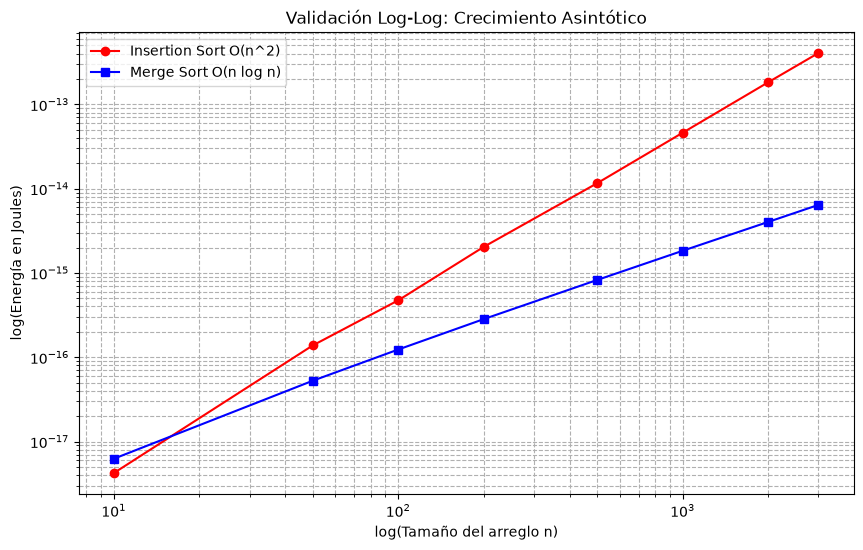

Pendiente de Insertion Sort: 1.99 (Teórico esperado ~ 2.0)
Pendiente de Merge Sort: 1.20 (Teórico esperado ~ 1.1)


In [6]:
plt.figure(figsize=(10, 6))
plt.loglog(n_values, energy_insertion, marker='o', color='red', label='Insertion Sort O(n^2)')
plt.loglog(n_values, energy_merge, marker='s', color='blue', label='Merge Sort O(n log n)')

# Calcular pendientes aproximadas usando polyfit en escala logarítmica
pendiente_ins = np.polyfit(np.log(n_values), np.log(energy_insertion), 1)[0]
pendiente_mer = np.polyfit(np.log(n_values), np.log(energy_merge), 1)[0]

plt.title('Validación Log-Log: Crecimiento Asintótico')
plt.xlabel('log(Tamaño del arreglo n)')
plt.ylabel('log(Energía en Joules)')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

print(f"Pendiente de Insertion Sort: {pendiente_ins:.2f} (Teórico esperado ~ 2.0)")
print(f"Pendiente de Merge Sort: {pendiente_mer:.2f} (Teórico esperado ~ 1.1)")

# Extra: Validación de Tiempos Reales

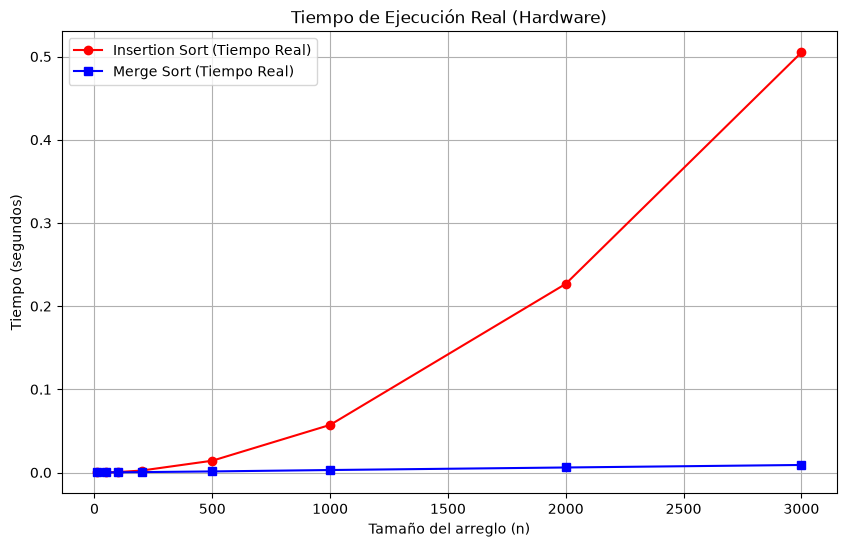

In [7]:
plt.figure(figsize=(10, 6))
plt.plot(n_values, time_insertion, marker='o', color='red', label='Insertion Sort (Tiempo Real)')
plt.plot(n_values, time_merge, marker='s', color='blue', label='Merge Sort (Tiempo Real)')

plt.title('Tiempo de Ejecución Real (Hardware)')
plt.xlabel('Tamaño del arreglo (n)')
plt.ylabel('Tiempo (segundos)')
plt.legend()
plt.grid(True)
plt.show()